# Image Embeddings Clustering and Visualization with HDBSCAN and t-SNE

In this notebook, I try to show that one can create image embeddings from crop images of the SKU110k dataset, cluster them with HDBSCAN and visualize the results with t-SNE including the actual images in the plot. This is useful to see if the crops are similar and if the clustering worked well.


Import Libraries

In [28]:
import matplotlib.pyplot as plt
import hdbscan
from sklearn.manifold import TSNE
from sklearn.preprocessing import normalize
import torch
from pathlib import Path
import numpy as np
from PIL import Image
import torchvision
from torchvision import transforms
from torchvision.models import ResNet50_Weights
import matplotlib

Try to speed up with GPU or DirectML if available

In [29]:

try:
    if torch.cuda.is_available():
        device = torch.device('cuda')
    else:
        try:
            import torch_directml
            device = torch_directml.device()
        except ImportError:
            device = torch.device('cpu')
except Exception:
    device = torch.device('cpu')

Load Pre-trained Model for Embeddings

In [30]:
weights = torchvision.models, ResNet50_Weights.IMAGENET1K_V2
model = torchvision.models.resnet50(weights=weights)

C:\Users\2dani\PycharmProject\ImageEmbeddings\.venv\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Remove Classification Layer for Feature Extraction

In [31]:
model = torch.nn.Sequential(*list(model.children())[:-1])
model = model.to(device)
model.eval()

Sequential(
  (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (4): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)


Image Preprocessing to Match Model Requirements

In [32]:
preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

Load all crop images from folder and create embeddings

In [33]:
crops_folder = Path(r"C:\Users\2dani\PycharmProject\ImageEmbeddings\data\crops\train\train_0\train_0")
image_paths = list(crops_folder.glob("*.jpg"))

print(f"Found {len(image_paths)} images")

embeddings_list = []
valid_image_paths = []

Found 141 images


Load image and create embeddings

In [34]:
with torch.no_grad():
    for img_path in image_paths:
        try:
            img = Image.open(img_path).convert('RGB')
            img_tensor = preprocess(img).unsqueeze(0).to(device)

            embedding = model(img_tensor)
            embedding = embedding.squeeze().cpu().numpy()

            embeddings_list.append(embedding)
            valid_image_paths.append(img_path)
        except Exception as e:
            print(f"Error processing {img_path}: {e}")

Turn embeddings list into numpy array

In [35]:
embeddings = np.array(embeddings_list)
print(f"Created embeddings with shape: {embeddings.shape}")

Created embeddings with shape: (141, 2048)


Normalize Embeddings for Cosine Distance

In [36]:
embeddings_normalized = normalize(embeddings, norm='l2')

print(f"EmbeddingsDialog Shape: {embeddings.shape}")

Embeddings Shape: (141, 2048)


Create DataFrame and Perform HDBSCAN Clustering

In [37]:
clusterer = hdbscan.HDBSCAN(min_cluster_size=3, metric='euclidean', core_dist_n_jobs=-1, algorithm='best')
labels = clusterer.fit_predict(embeddings_normalized)

print(f"Amount of clusters: {len(set(labels)) - (1 if -1 in labels else 0)}")
print(f"Amount of  noise points: {sum(labels == -1)}")

Amount of clusters: 5
Amount of  noise points: 103


# Data Visualization

Reduce Dimensions for Visualization

In [38]:
tsne = TSNE(n_components=2, random_state=42, metric='euclidean', perplexity=30, init='pca', n_jobs=-1)
e2d = tsne.fit_transform(embeddings_normalized)


Show a scatter plot of the clustered embeddings in 2D space

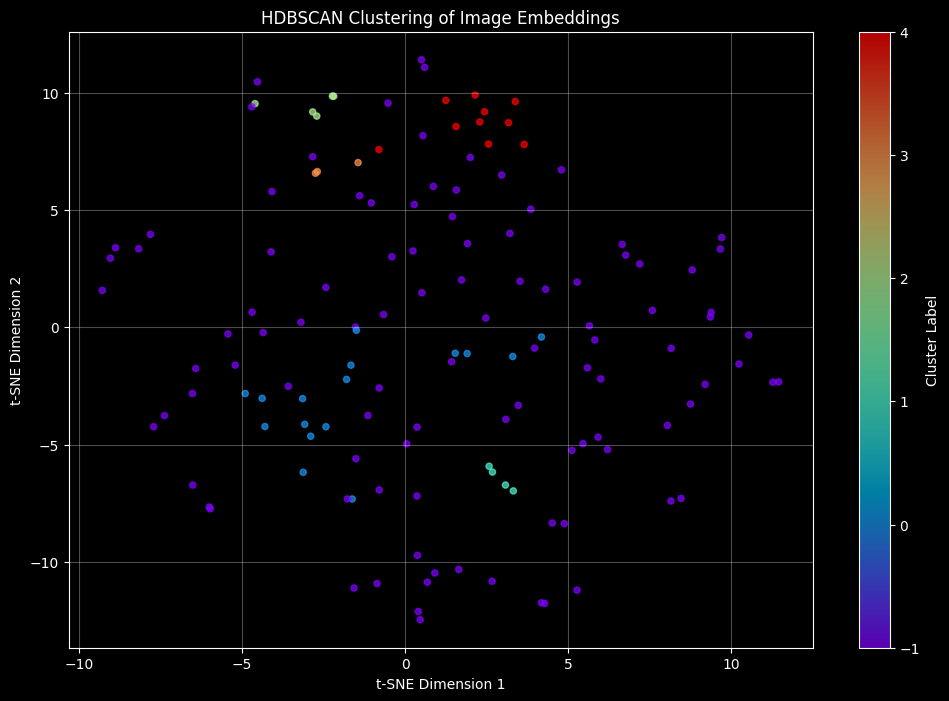

In [39]:
plt.figure(figsize=(12, 8))
plt.scatter(e2d[:, 0], e2d[:, 1], c=labels, cmap='rainbow', s=20, alpha=0.7)
plt.title('HDBSCAN Clustering of Image EmbeddingsDialog')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.colorbar(label='Cluster Label')
plt.grid(True, alpha=0.3)
plt.show()

Visualization with Images

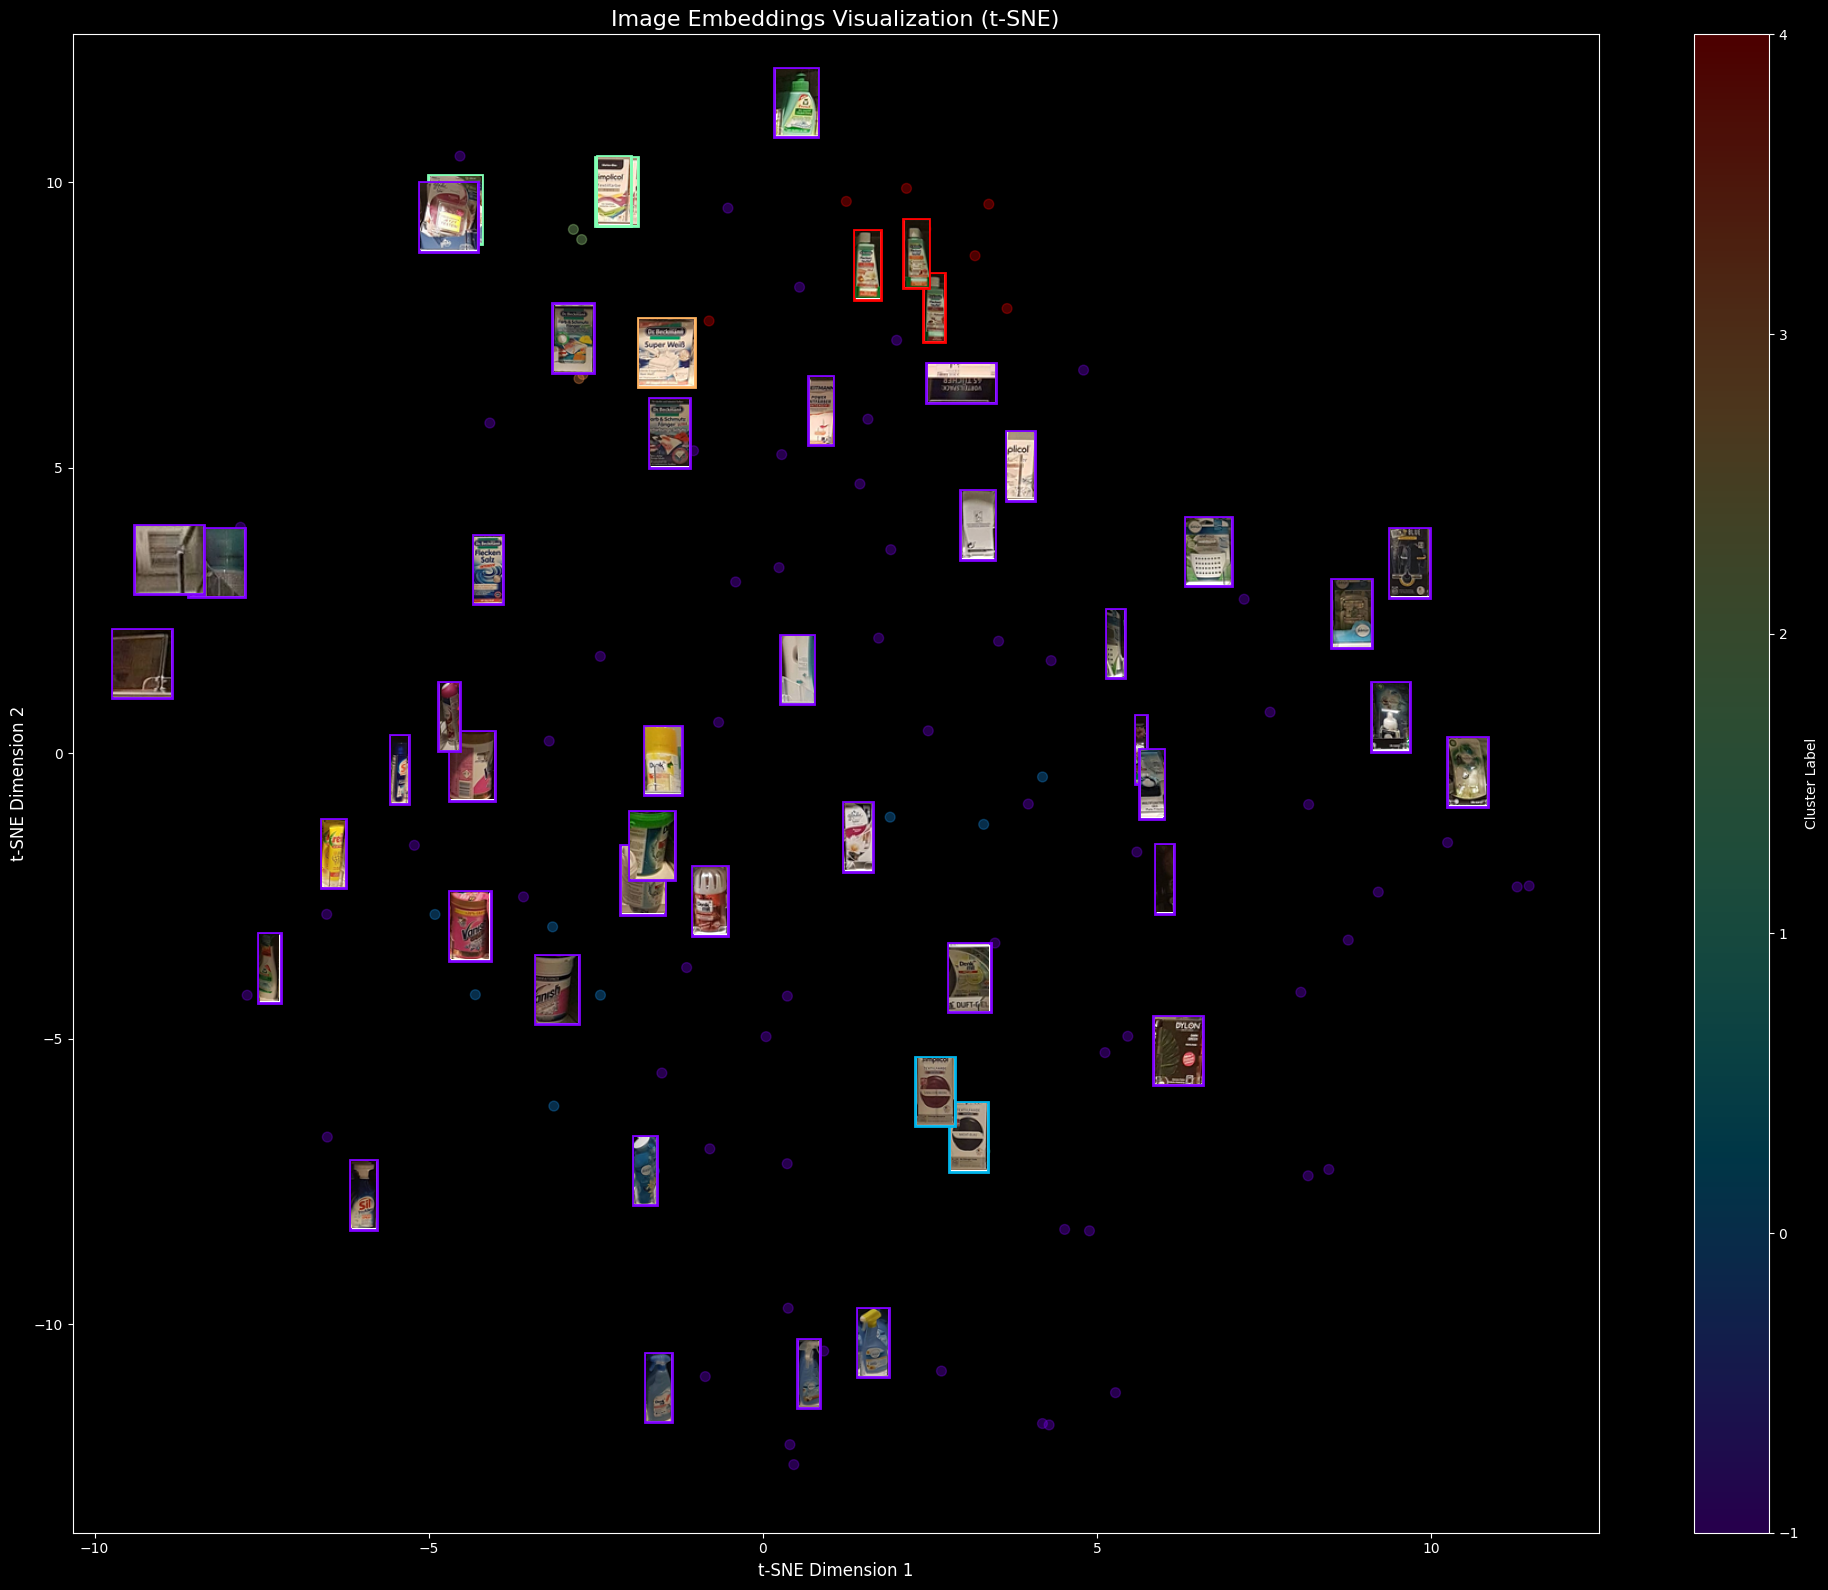

In [40]:
def plot_images_on_tsne(embeddings_2d, image_paths, labels, max_images=100, image_size=0.05):
    """
    Plot images on t-SNE scatter plot
    :param embeddings_2d: 2D embeddings from t-SNE
    :param image_paths: List of image file paths
    :param labels: Cluster labels for each image
    :param max_images: Maximum number of images to display
    :param image_size: Size of the images in the plot
    """
    fig, ax = plt.subplots(figsize=(20, 16))

    # Plot scatter for reference
    scatter = ax.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1],
                        c=labels, cmap='rainbow', s=50, alpha=0.3)

    # Choose a subset of images to display
    indices = np.linspace(0, len(image_paths) - 1, min(max_images, len(image_paths)), dtype=int)

    for idx in indices:
        try:
            # Load and resize image
            image = Image.open(image_paths[idx])
            image.thumbnail((60, 60), Image.Resampling.LANCZOS)

            # Create OffsetImage
            imagebox =  matplotlib.offsetbox.OffsetImage(image, zoom=image_size)

            # Position image at t-SNE coordinates
            ab =  matplotlib.offsetbox.AnnotationBbox(imagebox, (embeddings_2d[idx, 0], embeddings_2d[idx, 1]),
                               frameon=True, pad=0.1,
                               bboxprops=dict(edgecolor=plt.cm.rainbow(labels[idx] / max(labels)),
                                            linewidth=2))
            ax.add_artist(ab)
        except Exception as e:
            print(f"Error displaying image {image_paths[idx]}: {e}")

    ax.set_title('Image EmbeddingsDialog Visualization (t-SNE)', fontsize=16)
    ax.set_xlabel('t-SNE Dimension 1', fontsize=12)
    ax.set_ylabel('t-SNE Dimension 2', fontsize=12)
    plt.colorbar(scatter, label='Cluster Label', ax=ax)
    plt.tight_layout()
    plt.show()

# Create plot with images
plot_images_on_tsne(e2d, valid_image_paths, labels, max_images=50, image_size=0.8)

Interactive Plot with All Images (Grid View)

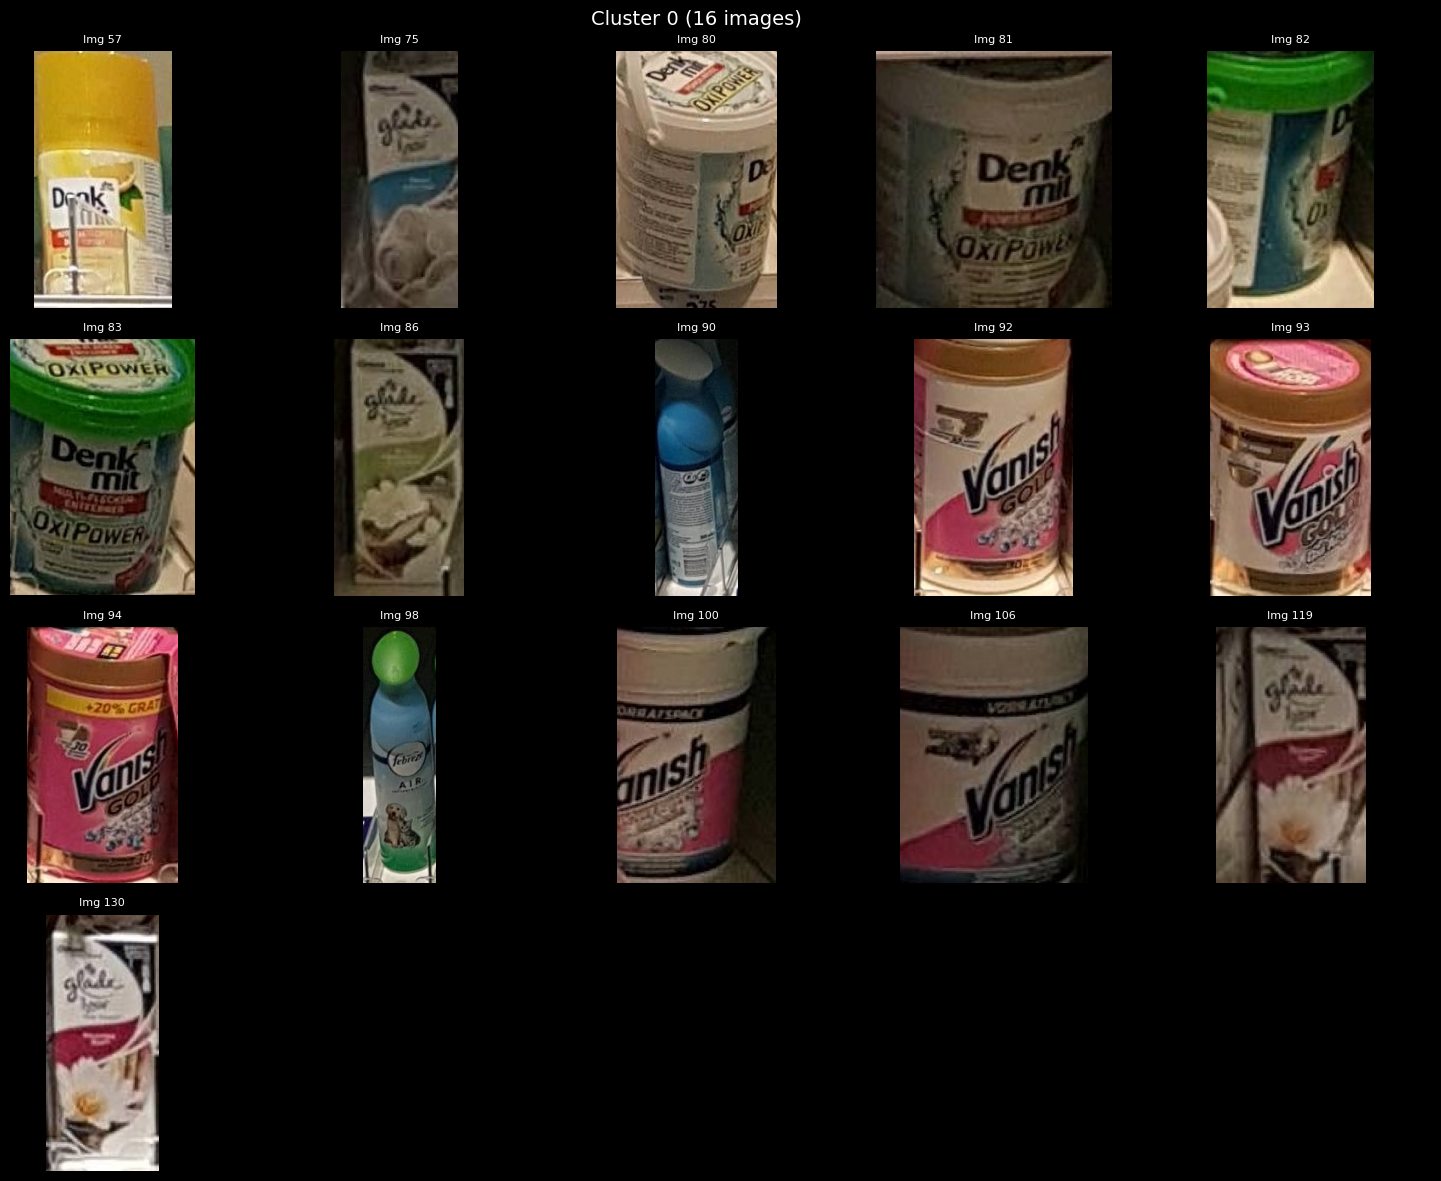

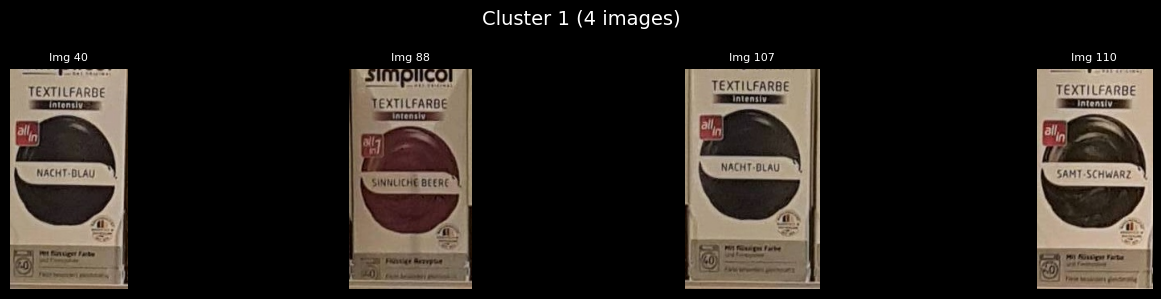

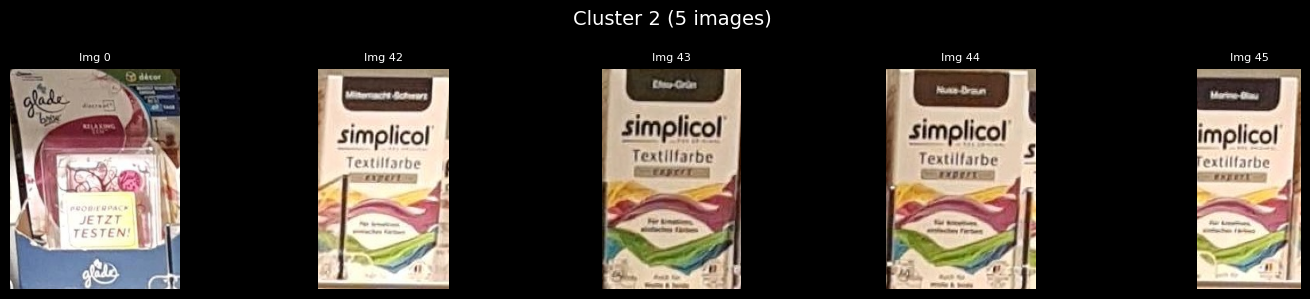

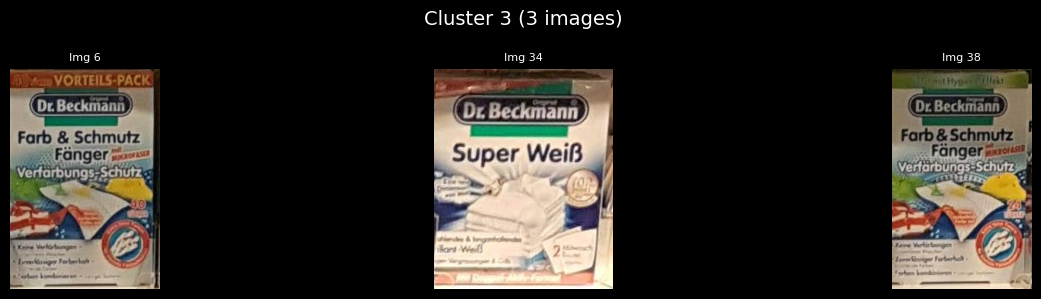

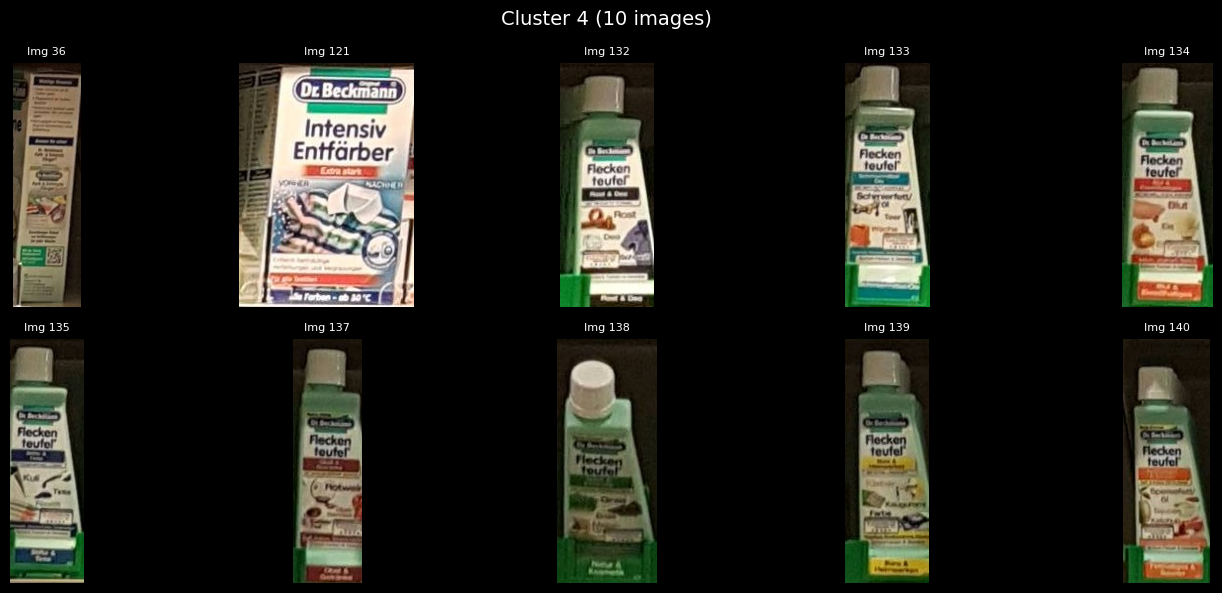

In [41]:
def plot_cluster_grid(image_paths, labels, cluster_id):
    """
    Plot a grid of images for a specific cluster
    :param image_paths: List of image file paths
    :param labels: Cluster labels for each image
    :param cluster_id: The cluster ID to plot
    """
    cluster_indices = np.where(labels == cluster_id)[0]

    if len(cluster_indices) == 0:
        print(f"No images in cluster {cluster_id}")
        return


    # Compute grid size
    cols = min(5, len(cluster_indices))
    rows = (len(cluster_indices) + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(15, 3 * rows))
    if len(cluster_indices) == 1:
        axes = [axes]
    else:
        axes = axes.flatten()

    for i, idx in enumerate(cluster_indices):
        image = Image.open(image_paths[idx])
        axes[i].imshow(image)
        axes[i].axis('off')
        axes[i].set_title(f"Img {idx}", fontsize=8)
    # Hide unused subplots
    for i in range(len(cluster_indices), len(axes)):
        axes[i].axis('off')

    plt.suptitle(f'Cluster {cluster_id} ({len(cluster_indices)} images)', fontsize=14)
    plt.tight_layout()
    plt.show()

# Show grids for clusters
unique_clusters = [c for c in set(labels) if c != -1]
for cluster_id in unique_clusters:
    plot_cluster_grid(valid_image_paths, labels, cluster_id)